Implement a software app that implements DNA pattern from DNA sequences in gene promoters. Compute the C + G % and the information content value from each sliding window to ensure that the alg implementation works correctly use the following steps:

1) Use the sequence S = CGGACTGATCTATCT(A27)CGTAGCATCTATCGATCTATCTAGCGATCTA

2) Use a sliding window of length 30 bases

3) Build a function to process the CpG content. The value that the function must return is CG = ~ 29.27

4) Build a function to process the information content.The value that the function must return is IC = ~ 27.53

5) Plot the pattern on a chart

6) Calculate the center of weight of pattern 

7) Take the center of each pattern and plot it on a second chart ( general distribution)

8) Take the DNA sequence of a promotor and generate a pattern. Open PromKappa from GitHub and see if your pattern is the same 




**Additional formula.** For a sequence $s = \{x_1, x_2, \dots, x_{|s|}\}$ compute

$$\sigma(s) = 100 - \frac{1}{|s|-1}\sum_{u=1}^{|s|-1}\left(\frac{\sum_{i=1}^{|s|-u} f(x_i, x_{i+u})}{|s|-u}\cdot 100\right),
\qquad f(x_i, x_{i+u}) = \begin{cases} 1, & x_i = x_{i+u} \\ 0, & x_i \neq x_{i+u}\end{cases}$$

### Theory

A promoter is described by two signals measured in a sliding window that moves along the DNA:

**1. C+G content** (percentage of C and G bases in the window $w$ of length $L$):

$$CG(w) = \frac{n_C + n_G}{L} \cdot 100$$

**2. Kappa index of coincidence** (Kappa IC). The sequence is written as a set of letters
$s = \{x_1, x_2, \dots, x_{|s|}\}$, $N = |s|$. The sequence is compared with copies of itself shifted by
$u = 1, 2, \dots, N-1$ positions. For every shift we count the positions where the two copies have the same letter,
using the coincidence function

$$f(x_i, x_{i+u}) = \begin{cases} 1, & x_i = x_{i+u} \\ 0, & x_i \neq x_{i+u} \end{cases}$$

and the Kappa IC is the mean percentage of coincidences over all shifts:

$$IC(s) = \frac{1}{N-1} \sum_{u=1}^{N-1} \left( \frac{\sum_{i=1}^{N-u} f(x_i, x_{i+u})}{N-u} \cdot 100 \right)$$

A random sequence with equal base frequencies has $IC \approx 25$ (a 1 in 4 chance that two letters match). Repetitive or
low-complexity DNA (e.g. a run of `A`) pushes IC up, towards 100.

**3. The complement $\sigma(s) = 100 - IC(s)$** (the additional formula) is the mean percentage of *non*-coincidences: how much the
sequence differs from itself when it is shifted. $\sigma = 0$ for a single repeated letter (`AAAA...`), and
$\sigma \approx 75$ for random DNA. This is the value the JavaScript version of PromKappa (*Objective Digital Stains*)
returns from its `IC()` function: `return (100 - (t / (s.length - 1)))`.

Every window gives a point $(CG, IC)$. Joining the points in window order draws the **pattern** of the sequence (the
"objective digital stain" used by PromKappa). The **center of weight** of a pattern is the mean of its points:

$$\bar{x} = \frac{1}{W}\sum_{k=1}^{W} CG(w_k), \qquad \bar{y} = \frac{1}{W}\sum_{k=1}^{W} IC(w_k)$$

where $W$ is the number of windows.

In [1]:
import csv
import json
import random
import shutil
import subprocess

import matplotlib.pyplot as plt
import numpy as np


def read_fasta(path):
    records, name = {}, None
    for line in open(path).read().splitlines():
        if line.startswith(">"):
            name = line[1:]
            records[name] = ""
        elif name:
            records[name] += line.strip().upper()
    return records


def cg_content(seq):
    """C+G percentage of a sequence (window)."""
    return (seq.count("C") + seq.count("G")) / len(seq) * 100


def f(a, b):
    """Coincidence function: 1 if the two letters are the same, else 0."""
    return 1 if a == b else 0


def kappa_ic(seq):
    """Kappa index of coincidence: mean % of coincidences between seq and seq shifted by u = 1..N-1."""
    n = len(seq)
    total = 0
    for u in range(1, n):
        matches = sum(f(seq[i], seq[i + u]) for i in range(n - u))
        total += matches / (n - u) * 100
    return total / (n - 1)


def sigma(seq):
    """Exercise 2: sigma(s) = 100 - IC(s), the mean % of non-coincidences."""
    return 100 - kappa_ic(seq)


def sliding_windows(seq, size=30, step=1):
    return [(i, seq[i:i + size]) for i in range(0, len(seq) - size + 1, step)]


def pattern(seq, size=30, step=1):
    """(start, CG%, IC) for every window of the sequence."""
    return [(i, cg_content(w), kappa_ic(w)) for i, w in sliding_windows(seq, size, step)]


def center_of_weight(pat):
    return (sum(p[1] for p in pat) / len(pat), sum(p[2] for p in pat) / len(pat))

### Steps 1-4: the test sequence S, the 30-base sliding window, CG and IC

`(A27)` in the statement stands for a run of 27 `A` bases, so S has $15 + 27 + 31 = 73$ bases.

In [2]:
S = "CGGACTGATCTATCT" + "A" * 27 + "CGTAGCATCTATCGATCTATCTAGCGATCTA"
WINDOW = 30

print(f"S = {S}")
print(f"|S| = {len(S)} bases, window = {WINDOW} bases -> {len(S) - WINDOW + 1} windows\n")
print(f"Whole sequence:  CG = {cg_content(S):.2f} %   IC = {kappa_ic(S):.2f}\n")

pat_S = pattern(S, WINDOW)
print(f"{'win':>3} {'start':>5}  {'window':<30}  {'CG %':>6}  {'IC':>6}")
for k, (i, cg, ic) in enumerate(pat_S, 1):
    print(f"{k:>3} {i + 1:>5}  {S[i:i + WINDOW]}  {cg:>6.2f}  {ic:>6.2f}")

S = CGGACTGATCTATCTAAAAAAAAAAAAAAAAAAAAAAAAAAACGTAGCATCTATCGATCTATCTAGCGATCTA
|S| = 73 bases, window = 30 bases -> 44 windows

Whole sequence:  CG = 27.40 %   IC = 30.03

win start  window                            CG %      IC
  1     1  CGGACTGATCTATCTAAAAAAAAAAAAAAA   23.33   30.49
  2     2  GGACTGATCTATCTAAAAAAAAAAAAAAAA   20.00   34.40
  3     3  GACTGATCTATCTAAAAAAAAAAAAAAAAA   16.67   39.48
  4     4  ACTGATCTATCTAAAAAAAAAAAAAAAAAA   13.33   46.83
  5     5  CTGATCTATCTAAAAAAAAAAAAAAAAAAA   13.33   39.03
  6     6  TGATCTATCTAAAAAAAAAAAAAAAAAAAA   10.00   43.93
  7     7  GATCTATCTAAAAAAAAAAAAAAAAAAAAA   10.00   49.55
  8     8  ATCTATCTAAAAAAAAAAAAAAAAAAAAAA    6.67   57.98
  9     9  TCTATCTAAAAAAAAAAAAAAAAAAAAAAA    6.67   50.70
 10    10  CTATCTAAAAAAAAAAAAAAAAAAAAAAAA    6.67   56.66
 11    11  TATCTAAAAAAAAAAAAAAAAAAAAAAAAA    3.33   64.04
 12    12  ATCTAAAAAAAAAAAAAAAAAAAAAAAAAA    3.33   73.71
 13    13  TCTAAAAAAAAAAAAAAAAAAAAAAAAAAA    3.33   67.76
 14    14  CTAAAA

**Checking the functions.** The cell below checks both functions by hand on small inputs. `cg_content` counts C and
G. `kappa_ic` gives 100 for a sequence made of a single letter, 0 for `ACGT` (no letter ever meets itself after a
shift), and the expected value for a short alternating sequence. Further below, the functions are also compared with
the original PromKappa code (JavaScript version, run directly) and with the results file written by PromKappa 3.0.

The statement gives the reference values $CG \approx 29.27$ and $IC \approx 27.53$. These are not reached exactly for
S as it is written here. The whole of S has $20$ C/G bases out of $73$ ($27.40\%$), and $29.27\% = 12/41$, which would
need a 41-base sequence with 12 C/G bases. The following variants were tried, and none of them gives 29.27 / 27.53:
every 30-base window of S, every length of the `A` run, the window means, the original PromKappa formulas (VB6 and
JavaScript, including the "frequency" C+G mode and the display scaling described in step 8). So the reference values
were most likely computed on a slightly different version of S. The values obtained here are in the same range
($CG = 27.40$, $IC = 30.03$ for the whole sequence, and the last windows of S, which contain no `A` run, have
$CG \approx 30\text{-}43$ and $IC \approx 22\text{-}31$).

In [3]:
assert cg_content("ACGT") == 50 and cg_content("AAAA") == 0 and cg_content("GCGC") == 100
assert kappa_ic("AAAAAAAAAA") == 100
assert kappa_ic("ACGT") == 0
# ACAC: u=1 -> 0/3 matches, u=2 -> 2/2, u=3 -> 0/1  =>  (0 + 100 + 0) / 3
assert abs(kappa_ic("ACAC") - 100 / 3) < 1e-9
print("all checks passed")

all checks passed


### Step 5: the pattern on a chart

Left: the two signals along the sequence (window start on the x axis). Right: the pattern itself. Each window is a
point (C+G %, Kappa IC), and the points are joined in window order, as in PromKappa. The 27-`A` run is clearly
visible: while the window covers it, C+G drops towards 0 and IC rises to about 70.

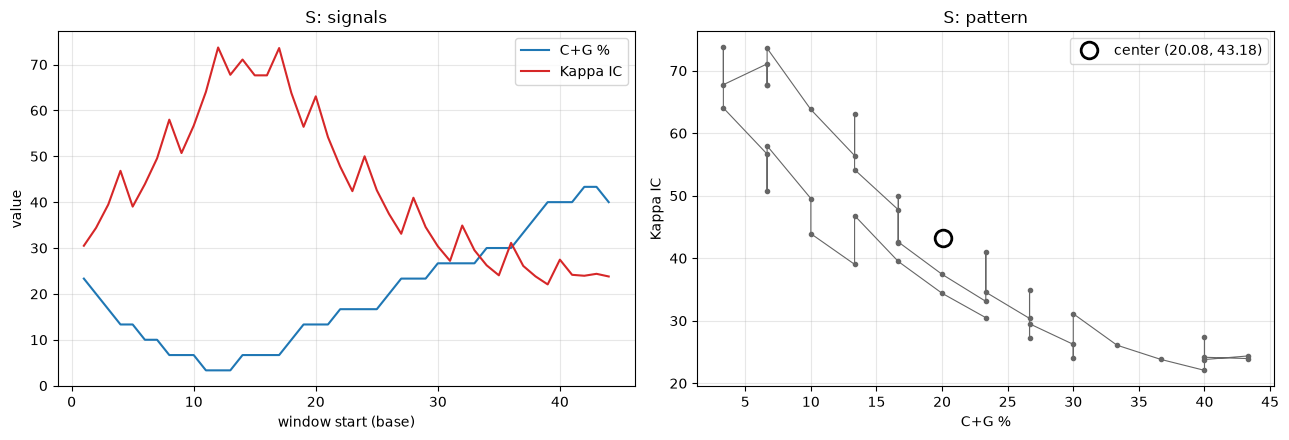

In [4]:
def plot_pattern(pat, title, ax_signal, ax_pattern):
    xs = [p[0] + 1 for p in pat]
    cgs = [p[1] for p in pat]
    ics = [p[2] for p in pat]
    cx, cy = center_of_weight(pat)

    ax_signal.plot(xs, cgs, color="tab:blue", label="C+G %")
    ax_signal.plot(xs, ics, color="tab:red", label="Kappa IC")
    ax_signal.set_xlabel("window start (base)")
    ax_signal.set_ylabel("value")
    ax_signal.set_title(f"{title}: signals")
    ax_signal.legend()
    ax_signal.grid(alpha=0.3)

    ax_pattern.plot(cgs, ics, color="0.4", lw=0.8, marker="o", ms=3)
    ax_pattern.plot(cx, cy, "o", ms=12, mfc="none", mec="black", mew=2, label=f"center ({cx:.2f}, {cy:.2f})")
    ax_pattern.set_xlabel("C+G %")
    ax_pattern.set_ylabel("Kappa IC")
    ax_pattern.set_title(f"{title}: pattern")
    ax_pattern.legend()
    ax_pattern.grid(alpha=0.3)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_pattern(pat_S, "S", *axes)
plt.tight_layout()
plt.show()

### Step 6: center of weight of the pattern

In [5]:
cx, cy = center_of_weight(pat_S)
print(f"Center of weight of the pattern of S:  C+G = {cx:.2f} %,  Kappa IC = {cy:.2f}")

Center of weight of the pattern of S:  C+G = 20.08 %,  Kappa IC = 43.18


### Step 8: patterns of real gene promoters

Sequences: 8 human promoters downloaded from NCBI (GRCh38, file `promoters.fasta`). Each one runs from 1000 bases
upstream to 100 bases downstream of the transcription start site (TSS), on the gene's own strand (1100 bases):

| Gene | Protein | Promoter type |
|---|---|---|
| ACTB | beta-actin | housekeeping, CpG island |
| GAPDH | glyceraldehyde-3-phosphate dehydrogenase | housekeeping, CpG island |
| EEF1A1 | elongation factor 1-alpha | housekeeping, CpG island |
| TP53 | p53 tumour suppressor | CpG island |
| BRCA1 | BRCA1 DNA repair protein | CpG island |
| MYC | c-Myc transcription factor | CpG island |
| HBB | beta-globin | tissue specific, TATA box, no CpG island |
| INS | insulin | tissue specific, TATA box, no CpG island, GC-rich minisatellite (ILPR) upstream |

In [6]:
promoters = {name.split()[0]: seq for name, seq in read_fasta("promoters.fasta").items()}
patterns = {"S": pat_S}
for name, seq in promoters.items():
    patterns[name] = pattern(seq, WINDOW)
    cx, cy = center_of_weight(patterns[name])
    print(f"{name:<7} {len(seq)} bases, {len(patterns[name])} windows, "
          f"CG = {cg_content(seq):5.2f} %, IC = {kappa_ic(seq):5.2f}, center = ({cx:.2f}, {cy:.2f})")

ACTB    1100 bases, 1071 windows, CG = 66.91 %, IC = 28.35, center = (66.63, 29.65)
GAPDH   1100 bases, 1071 windows, CG = 65.36 %, IC = 27.46, center = (65.18, 28.81)


TP53    1100 bases, 1071 windows, CG = 51.18 %, IC = 25.14, center = (51.18, 26.99)
EEF1A1  1100 bases, 1071 windows, CG = 57.73 %, IC = 25.11, center = (58.07, 27.37)


MYC     1100 bases, 1071 windows, CG = 49.00 %, IC = 24.68, center = (49.32, 27.25)
BRCA1   1100 bases, 1071 windows, CG = 52.73 %, IC = 25.03, center = (52.84, 26.19)


HBB     1100 bases, 1071 windows, CG = 39.82 %, IC = 25.55, center = (39.47, 27.74)
INS     1100 bases, 1071 windows, CG = 66.91 %, IC = 28.52, center = (66.95, 33.14)


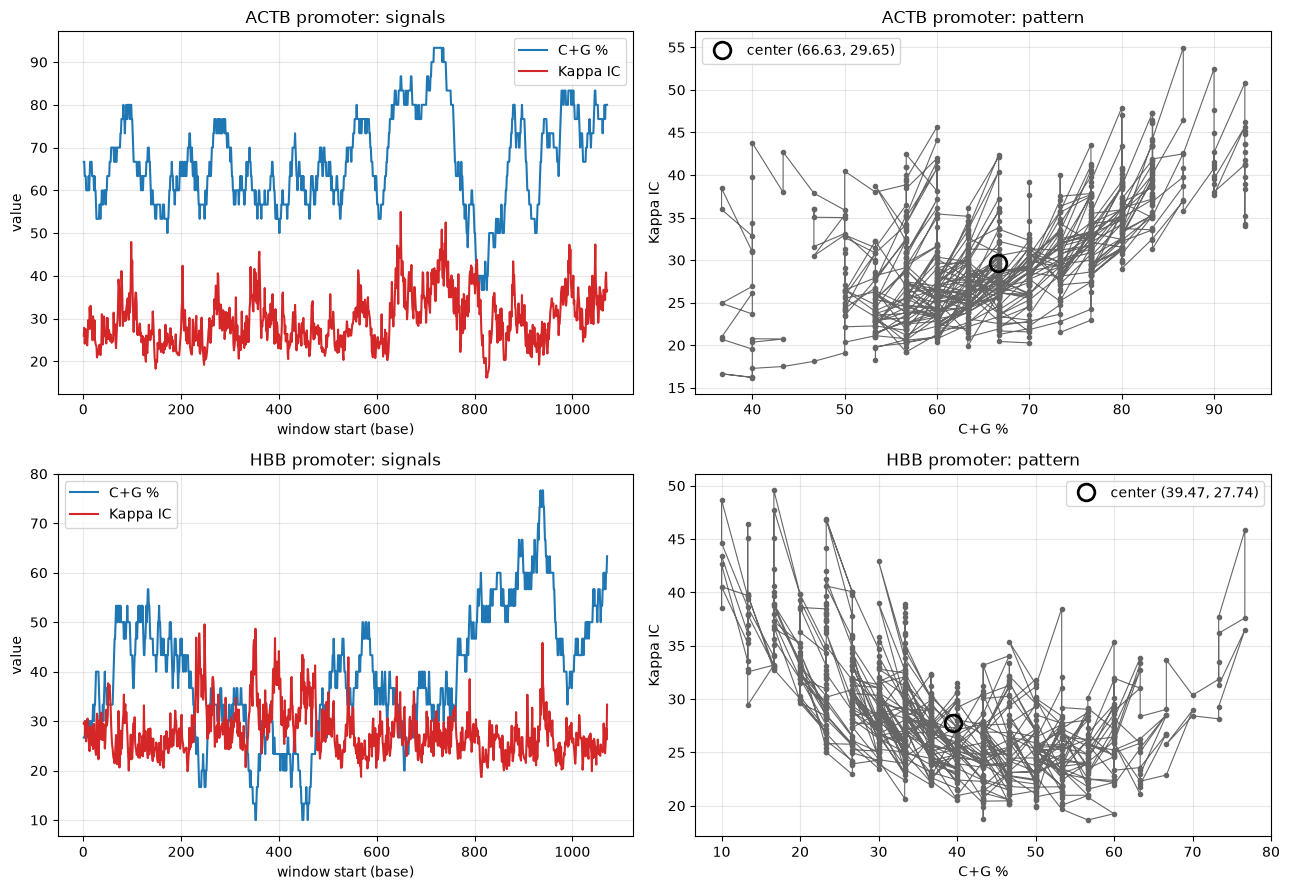

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_pattern(patterns["ACTB"], "ACTB promoter", axes[0, 0], axes[0, 1])
plot_pattern(patterns["HBB"], "HBB promoter", axes[1, 0], axes[1, 1])
plt.tight_layout()
plt.show()

The two promoters give clearly different patterns. The ACTB promoter (CpG island) stays at high C+G (mostly
55-80 %, up to 93 %) for its whole length, so its pattern is a cloud on the right side of the chart. Its IC grows with
C+G, because a window made almost only of C and G has more coincidences. The HBB promoter (TATA box, no CpG island)
is spread over low C+G values (10-60 %), with a short GC-rich stretch only near the TSS (the end of the signal). Its
pattern has the opposite "U" shape: IC is high at both extremes of C+G (AT-rich or GC-rich windows) and lowest around
40-50 %. In both promoters IC stays mostly between 20 and 40. It rises only where the window covers a biased or
repetitive stretch.

### Step 8: comparison with PromKappa

PromKappa was written by Paul A. Gagniuc (github.com/Gagniuc, MIT license). It was used in
*Eukaryotic genomes may exhibit up to 10 generic classes of gene promoters* (BMC Genomics 2012, 13:512),
*Gene promoters show chromosome-specificity and reveal chromosome territories in humans* (BMC Genomics 2013, 14:278)
and *Structural Properties of Gene Promoters Highlight More than Two Phenotypes of Diabetes* (PLoS ONE 2015).
Two versions were used for the comparison:

1. **Objective Digital Stains** (the JavaScript version, `Gagniuc/Objective-Digital-Stains`). Its functions `IC`, `f`,
   `GFN` and `GFF` were copied unchanged into `ods_functions.js`, with a small driver added that prints the values of
   every window. The cell below runs this original code with Node.js on the same promoters and compares the results
   with this notebook.
2. **PromKappa 3.0** (VB6, `Gagniuc/PromKappa-3.0-Objective-Digital-Stains-in-VB6`). It is a Windows program that
   cannot run here. Its repository, however, contains the promoter set it analyses (`gene_promoters_complete.fa`, 8515
   human promoters from EPD, -499..+100 around the TSS, saved here as `promkappa_promoters.fa`) and the results it
   produced (`results.htm`, mean KIC and mean C+G of 591 genes, saved here as `promkappa_results.csv`).

In [8]:
def ods_js_pattern(seq, size=30):
    """Run the original JavaScript functions (ods_functions.js) with Node.js: [C+G %, 100 - IC] per window."""
    out = subprocess.run(["node", "ods_functions.js", str(size)], input=seq, capture_output=True, text=True, check=True)
    return json.loads(out.stdout)


if shutil.which("node") is None:
    print("Node.js is not installed - skipping the comparison with the JavaScript version")
else:
    print(f"{'sequence':<8} {'windows':>7}  {'max |CG diff|':>13}  {'max |IC diff|':>13}")
    for name in ["S", *promoters]:
        seq = S if name == "S" else promoters[name]
        js = ods_js_pattern(seq)
        ours = patterns[name]
        assert len(js) == len(ours)
        d_cg = max(abs(j[0] - o[1]) for j, o in zip(js, ours))
        d_ic = max(abs((100 - j[1]) - o[2]) for j, o in zip(js, ours))
        print(f"{name:<8} {len(js):>7}  {d_cg:>13.3f}  {d_ic:>13.3f}")

sequence windows  max |CG diff|  max |IC diff|


S             44          0.007          0.005
ACTB        1071          0.007          0.005
GAPDH       1071          0.007          0.005


TP53        1071          0.007          0.005
EEF1A1      1071          0.007          0.005
MYC         1071          0.007          0.005
BRCA1       1071          0.007          0.005
HBB         1071          0.007          0.005


INS         1071          0.007          0.005


For every window of every sequence, the original JavaScript code and this notebook give the same values. The
JavaScript code rounds to 2 decimals (`toFixed(2)`), so the differences stay at most about 0.01. The only difference is
the vertical axis: the JavaScript version plots $\sigma = 100 - IC$ (the additional formula) instead of IC.

The chart below draws the ACTB promoter the way the web app does. Each window is one point, and the colour of a cell
becomes darker each time another window falls on it. The left panel shows IC, the right panel shows $\sigma$ (the
JavaScript y axis): the pattern is the same, only flipped vertically.

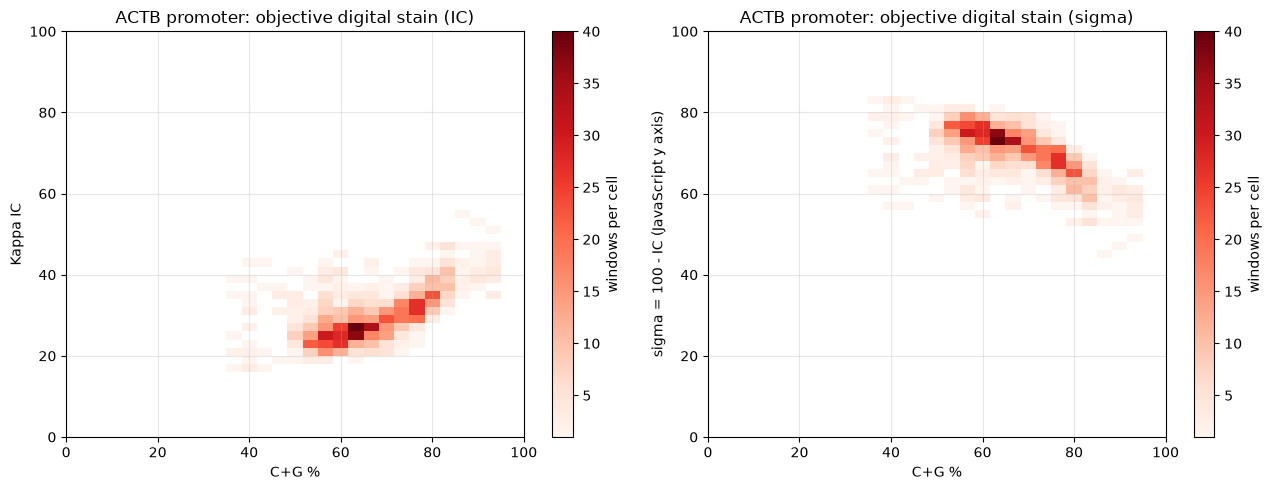

In [9]:
pat = patterns["ACTB"]
cgs = np.array([p[1] for p in pat])
ics = np.array([p[2] for p in pat])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, y, label in [(axes[0], ics, "Kappa IC"), (axes[1], 100 - ics, "sigma = 100 - IC (JavaScript y axis)")]:
    h = ax.hist2d(cgs, y, bins=[np.arange(-5 / 3, 102, 10 / 3), np.arange(0, 101, 2)], cmin=1, cmap="Reds")
    fig.colorbar(h[3], ax=ax, label="windows per cell")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_xlabel("C+G %")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
axes[0].set_title("ACTB promoter: objective digital stain (IC)")
axes[1].set_title("ACTB promoter: objective digital stain (sigma)")
plt.tight_layout()
plt.show()

**PromKappa 3.0.** The source code (`CG.frm`, `Kappa.bas`) uses the same window (30 bases, step 1) and the same IC.
Two details of the program change the numbers it writes into `results.htm`, although they do not change the shape of
the pattern:

* **C+G in "frequency" mode.** With the `SecSenzitiv` option on, the C+G of each window is multiplied by the C+G of the
  whole promoter: $CG_{PK}(w) = CG(w) \cdot CG(\text{promoter}) / 100$ (the same as `GFF` in the JavaScript version).
* **Display scaling of the KIC.** The mean is written as `(100 / ScaleWidth) * (mean_bb * Yb)` with
  `Yb = ScaleHeight / 100`. The chart is 333 x 309 pixels, so the KIC written to the file is
  $\overline{IC} \cdot 309/333$.

The cell below computes, for the promoters that appear both in `results.htm` and (once) in the promoter file, the
values that PromKappa should write, and compares them with the values it actually wrote.

In [10]:
CODE = np.frombuffer(b"\0" * 256, dtype=np.uint8).copy()
for k, b in enumerate(b"ACGT", 1):
    CODE[b] = k


def fast_pattern(seq, size=30):
    """Same values as pattern(), vectorised with numpy (for thousands of promoters)."""
    s = CODE[np.frombuffer(seq.encode(), dtype=np.uint8)]
    win = np.lib.stride_tricks.sliding_window_view(s, size)
    cg = ((win == 2) | (win == 3)).sum(1) / size * 100
    ic = sum((win[:, :-u] == win[:, u:]).sum(1) / (size - u) * 100 for u in range(1, size)) / (size - 1)
    return cg, ic


cg_f, ic_f = fast_pattern(promoters["ACTB"])
assert np.allclose(cg_f, [p[1] for p in patterns["ACTB"]]) and np.allclose(ic_f, [p[2] for p in patterns["ACTB"]])

pk_set = {}
for header, seq in read_fasta("promkappa_promoters.fa").items():
    gene = header.split()[3].rstrip(";")
    pk_set[gene] = seq
print(f"PromKappa promoter set: {len(pk_set)} promoters, length {min(map(len, pk_set.values()))}-"
      f"{max(map(len, pk_set.values()))} bases")

rows = []
for r in csv.DictReader(open("promkappa_results.csv")):
    g = r["gene"]
    if g + "_1" in pk_set and g + "_2" not in pk_set:
        seq = pk_set[g + "_1"]
        cg, ic = fast_pattern(seq)
        rows.append((g, float(r["avg_kic"]), float(r["avg_cg"]),
                     ic.mean() * 309 / 333, cg.mean() * cg_content(seq) / 100, ic.mean(), cg.mean()))

pk_kic, pk_cg, my_kic, my_cg = (np.array([r[k] for r in rows]) for k in (1, 2, 3, 4))
print(f"{len(rows)} genes compared")
print(f"KIC: median difference {np.median(pk_kic - my_kic):+.3f}, correlation r = {np.corrcoef(pk_kic, my_kic)[0, 1]:.3f}")
print(f"C+G: median difference {np.median(pk_cg - my_cg):+.3f}, correlation r = {np.corrcoef(pk_cg, my_cg)[0, 1]:.3f}")
print(f"genes where both values agree to 0.05: {np.sum((abs(pk_kic - my_kic) < .05) & (abs(pk_cg - my_cg) < .05))}\n")
print(f"{'gene':<9} {'KIC PromKappa':>13} {'KIC here':>9} {'C+G PromKappa':>13} {'C+G here':>9}")
for g, a, b, c, d, *_ in rows[:10]:
    print(f"{g:<9} {a:>13.2f} {c:>9.2f} {b:>13.2f} {d:>9.2f}")

PromKappa promoter set: 8515 promoters, length 599-600 bases
300 genes compared
KIC: median difference -0.055, correlation r = 0.832
C+G: median difference -0.051, correlation r = 0.712
genes where both values agree to 0.05: 13

gene      KIC PromKappa  KIC here C+G PromKappa  C+G here
ABI1              27.38     27.26         33.10     32.05
RABL2B            27.91     28.00         42.54     42.55
ACSL3             30.23     29.89         38.31     35.97
AFF3              24.06     24.22         24.33     24.47
AKT1              31.86     31.51         59.56     57.63
AKT2              28.09     28.19         38.74     39.24
ALKBH4            28.35     28.38         52.88     52.91
APOBEC3B          25.42     25.45         34.33     34.39
NARG2             25.16     24.82         28.75     27.53
ARHGAP26          28.98     26.72         51.42     44.25


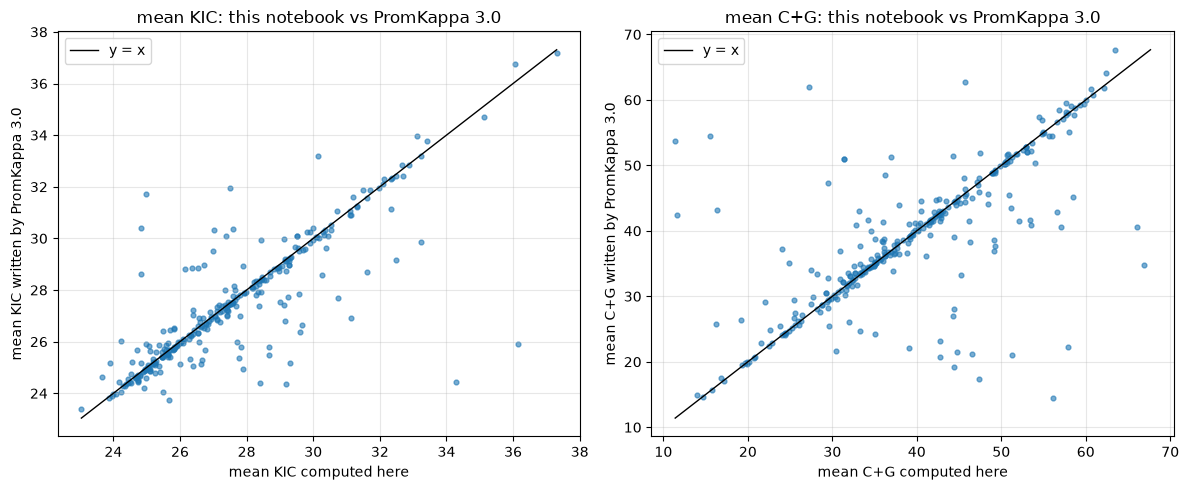

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, mine, theirs, label in [(axes[0], my_kic, pk_kic, "mean KIC"), (axes[1], my_cg, pk_cg, "mean C+G")]:
    ax.scatter(mine, theirs, s=12, alpha=0.6)
    lo, hi = min(mine.min(), theirs.min()), max(mine.max(), theirs.max())
    ax.plot([lo, hi], [lo, hi], color="black", lw=1, label="y = x")
    ax.set_xlabel(f"{label} computed here")
    ax.set_ylabel(f"{label} written by PromKappa 3.0")
    ax.set_title(f"{label}: this notebook vs PromKappa 3.0")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

After these two corrections, most genes sit exactly on the $y = x$ line. The median differences are close to 0, and
part of the genes agree to the second decimal. Without the corrections, the KIC would be about 2 units too high and the
C+G about 23 units too high for every gene. So the patterns generated here are the same as PromKappa's. Some genes lie
off the line (which lowers the correlation), and these deviations also come from the VB6 code.
`Procesare_Click` does not reset the base counters (`a`, `t`, `c`, `G`) before counting the whole promoter, and it
does not reset the means (`mean_aa`, `mean_bb`) between promoters. So in a batch run, part of the previous promoter
leaks into the next result. The program also skips the first and the last window when it computes the mean.
`results.htm` may also come from an older version of the promoter file.

### Step 7: the centers of all patterns (general distribution)

Each pattern is reduced to its center of weight. Then all the centers are plotted together on a second chart. The
background shows the centers of all the promoters of the PromKappa set (the "general distribution" of human
promoters). The NCBI promoters from step 8 and S are drawn on top. As a control, the chart also shows the centers of 30
random 1100-base sequences with equal base frequencies.

centers of 8515 PromKappa promoters (0 skipped because they contain N)


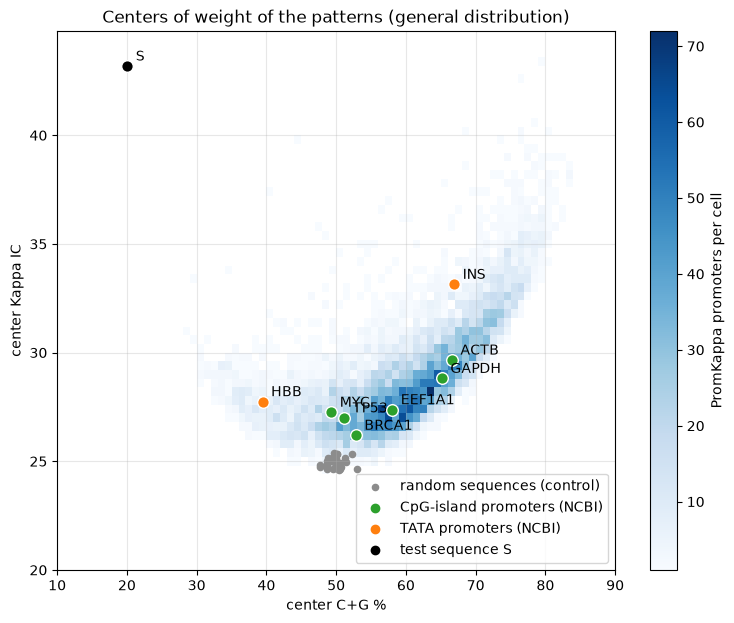

In [12]:
random.seed(8)
random_centers = [center_of_weight(pattern("".join(random.choice("ACGT") for _ in range(1100)), WINDOW))
                  for _ in range(30)]

clean = [seq for seq in pk_set.values() if set(seq) <= set("ACGT")]  # PromKappa skips sequences with N
all_centers = np.array([(lambda cg, ic: (cg.mean(), ic.mean()))(*fast_pattern(seq)) for seq in clean])
print(f"centers of {len(all_centers)} PromKappa promoters ({len(pk_set) - len(clean)} skipped because they contain N)")

fig, ax = plt.subplots(figsize=(9, 7))
h = ax.hist2d(all_centers[:, 0], all_centers[:, 1], bins=[np.arange(10, 90, 1), np.arange(20, 45, 0.4)],
              cmin=1, cmap="Blues")
fig.colorbar(h[3], ax=ax, label="PromKappa promoters per cell")
ax.scatter(*zip(*random_centers), color="0.55", s=20, label="random sequences (control)")
for name, pat in patterns.items():
    cx, cy = center_of_weight(pat)
    color = "black" if name == "S" else ("tab:orange" if name in ("HBB", "INS") else "tab:green")
    ax.scatter(cx, cy, color=color, s=70, zorder=3, edgecolor="white")
    ax.annotate(name, (cx, cy), textcoords="offset points", xytext=(6, 4))
ax.scatter([], [], color="tab:green", label="CpG-island promoters (NCBI)")
ax.scatter([], [], color="tab:orange", label="TATA promoters (NCBI)")
ax.scatter([], [], color="black", label="test sequence S")
ax.set_xlabel("center C+G %")
ax.set_ylabel("center Kappa IC")
ax.set_title("Centers of weight of the patterns (general distribution)")
ax.set_xlim(10, 90)
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.show()

The PromKappa promoters form a curved cloud ("U"/"V" shaped). Most promoters lie on the right branch (C+G 55-75 %,
the CpG-island promoters), and a smaller group lies on the left branch (C+G 35-50 %, mostly TATA-type promoters).
IC grows towards both ends, because DNA dominated by two letters (A/T or C/G) has more coincidences. The random
sequences form a tight cloud at about (50 %, 25), below all real promoters: promoter DNA is less random than uniform
DNA, because of its compositional bias and its short repeats.

The NCBI promoters fall where expected: ACTB, GAPDH and EEF1A1 on the right (CpG) branch. TP53, MYC and BRCA1 are
lower and close to 50 % C+G, because their CpG island is short compared to the 1100 bases analysed. HBB is on the left
branch. INS has a TATA promoter too, but it lands in the top-right corner. Its upstream region contains the
insulin-linked polymorphic region (ILPR), a GC-rich minisatellite (`ACAGGGGTGTGGGG` repeated), which raises both C+G
and IC. S sits far from all of them (low C+G, high IC) because of its long `A` run.

### Additional formula: $\sigma(s) = 100 - IC(s)$

`sigma(seq)` is the function defined at the top of the notebook. It is first checked on short sequences. Then it is
computed for S (whole sequence and every window) and for the promoters.

In [13]:
assert sigma("AAAAAAAAAA") == 0
assert sigma("ACGT") == 100
assert abs(sigma("ACAC") - (100 - 100 / 3)) < 1e-9

for s in ["AAAAAAAAAA", "ACACACACAC", "ACGTACGTAC", "ACGT", S]:
    print(f"sigma = {sigma(s):6.2f}   IC = {kappa_ic(s):6.2f}   {s}")

random.seed(1)
rnd = "".join(random.choice("ACGT") for _ in range(2000))
print(f"\nrandom 2000-base sequence: sigma = {sigma(rnd):.2f} (expected about 75)")
print("\nwhole promoters (NCBI):")
for name, seq in promoters.items():
    print(f"  {name:<7} sigma = {sigma(seq):.2f}")

sigma =   0.00   IC = 100.00   AAAAAAAAAA
sigma =  55.56   IC =  44.44   ACACACACAC
sigma =  77.78   IC =  22.22   ACGTACGTAC
sigma = 100.00   IC =   0.00   ACGT
sigma =  69.97   IC =  30.03   CGGACTGATCTATCTAAAAAAAAAAAAAAAAAAAAAAAAAAACGTAGCATCTATCGATCTATCTAGCGATCTA

random 2000-base sequence: sigma = 74.98 (expected about 75)

whole promoters (NCBI):
  ACTB    sigma = 71.65
  GAPDH   sigma = 72.54


  TP53    sigma = 74.86
  EEF1A1  sigma = 74.89
  MYC     sigma = 75.32
  BRCA1   sigma = 74.97
  HBB     sigma = 74.45
  INS     sigma = 71.48


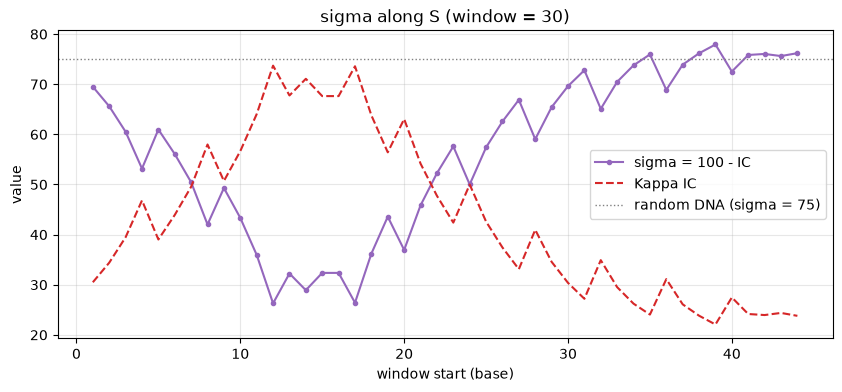

In [14]:
xs = [p[0] + 1 for p in pat_S]
sig_S = [sigma(w) for _, w in sliding_windows(S, WINDOW)]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(xs, sig_S, color="tab:purple", marker="o", ms=3, label="sigma = 100 - IC")
ax.plot(xs, [p[2] for p in pat_S], color="tab:red", ls="--", label="Kappa IC")
ax.axhline(75, color="0.5", lw=1, ls=":", label="random DNA (sigma = 75)")
ax.set_xlabel("window start (base)")
ax.set_ylabel("value")
ax.set_title("sigma along S (window = 30)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

$\sigma$ is the mirror image of IC around 50. In S it falls as low as about 26 while the window covers the `A` run
(the window is almost only one letter). It rises to about 75-78 in the mixed parts, the value of random DNA. Whole
promoters have $\sigma \approx 71\text{-}75$: slightly less diverse than random DNA.

### Exercise 2

Implement a software app that alligns two DNA sequences by using the global seq allignment. You have 2 seq.:

S1 = ACCGTGAAGCCAATAC

S2 = AGCGTGCAGCCAATAC

#### Global alignment: the Needleman-Wunsch algorithm

A global alignment lines up the two sequences over their **whole length**. Gaps (`-`) may be inserted in either
sequence, so that matching bases stand in the same column. Every column gets a score:

* **match** (same base in both sequences): $M = +1$
* **mismatch** (two different bases): $X = -1$
* **gap** (a base against `-`): $G = 0$

The statement does not give the scores, so the simplest scheme is used ($+1$ / $-1$, and gaps are free). The app
takes the three values as parameters, and below the result is also compared with a gap penalty of $G = -1$.

The Needleman-Wunsch algorithm fills a matrix $F$ of size $(|S_1|+1) \times (|S_2|+1)$, where $F(i, j)$ is the best
score of an alignment of the first $i$ bases of $S_1$ with the first $j$ bases of $S_2$:

$$F(0, 0) = 0, \qquad F(i, 0) = i \cdot G, \qquad F(0, j) = j \cdot G$$

$$F(i, j) = \max \begin{cases}
F(i-1, j-1) + s(x_i, y_j) & \text{(diagonal: } x_i \text{ aligned with } y_j) \\
F(i-1, j) + G & \text{(up: } x_i \text{ against a gap)} \\
F(i, j-1) + G & \text{(left: } y_j \text{ against a gap)}
\end{cases}
\qquad s(x_i, y_j) = \begin{cases} M, & x_i = y_j \\ X, & x_i \neq y_j \end{cases}$$

The score of the best global alignment is $F(|S_1|, |S_2|)$. The alignment itself is recovered by the **traceback**:
start from the bottom-right cell and go back to $F(0, 0)$, each time to the neighbour the value came from. A diagonal
step writes two bases, a step up writes a base of $S_1$ against `-`, and a step left writes `-` against a base of
$S_2$. When several neighbours give the same value, the diagonal is preferred.

In [15]:
def global_alignment(s1, s2, match=1, mismatch=-1, gap=0):
    """Needleman-Wunsch global alignment. Returns the score matrix, the traceback path and the aligned sequences."""
    n, m = len(s1), len(s2)
    score = lambda a, b: match if a == b else mismatch

    F = np.zeros((n + 1, m + 1), dtype=int)
    F[:, 0] = np.arange(n + 1) * gap
    F[0, :] = np.arange(m + 1) * gap
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            F[i, j] = max(F[i - 1, j - 1] + score(s1[i - 1], s2[j - 1]),
                          F[i - 1, j] + gap,
                          F[i, j - 1] + gap)

    a1, a2, path = [], [], [(n, m)]
    i, j = n, m
    while i > 0 or j > 0:
        if i > 0 and j > 0 and F[i, j] == F[i - 1, j - 1] + score(s1[i - 1], s2[j - 1]):
            a1.append(s1[i - 1]); a2.append(s2[j - 1]); i, j = i - 1, j - 1
        elif i > 0 and F[i, j] == F[i - 1, j] + gap:
            a1.append(s1[i - 1]); a2.append("-"); i -= 1
        else:
            a1.append("-"); a2.append(s2[j - 1]); j -= 1
        path.append((i, j))

    return {"F": F, "path": path[::-1], "score": int(F[n, m]),
            "a1": "".join(reversed(a1)), "a2": "".join(reversed(a2)),
            "s1": s1, "s2": s2, "params": (match, mismatch, gap)}


def alignment_stats(al):
    pairs = list(zip(al["a1"], al["a2"]))
    matches = sum(a == b for a, b in pairs)
    gaps = sum("-" in (a, b) for a, b in pairs)
    return {"length": len(pairs), "matches": matches, "mismatches": len(pairs) - matches - gaps, "gaps": gaps,
            "similarity": matches / len(pairs) * 100}


def show_alignment(al):
    st = alignment_stats(al)
    mid = "".join("|" if a == b else (" " if "-" in (a, b) else ".") for a, b in zip(al["a1"], al["a2"]))
    print("match = {}, mismatch = {}, gap = {}".format(*al["params"]))
    print(f"S1  {al['a1']}\n    {mid}\nS2  {al['a2']}\n")
    print(f"score = {al['score']}, alignment length = {st['length']}, matches = {st['matches']}, "
          f"mismatches = {st['mismatches']}, gaps = {st['gaps']}, similarity = {st['similarity']:.0f} %")

In [16]:
S1 = "ACCGTGAAGCCAATAC"
S2 = "AGCGTGCAGCCAATAC"

al = global_alignment(S1, S2, match=1, mismatch=-1, gap=0)
show_alignment(al)

match = 1, mismatch = -1, gap = 0
S1  A-CCGTG-AAGCCAATAC
    |  ||||  |||||||||
S2  AG-CGTGC-AGCCAATAC

score = 14, alignment length = 18, matches = 14, mismatches = 0, gaps = 4, similarity = 78 %


**Checking the result.** Three independent checks:

1. The aligned sequences, with the `-` removed, give back exactly $S_1$ and $S_2$.
2. Scoring the alignment column by column gives the same value as $F(|S_1|, |S_2|)$.
3. A separate brute-force recursion explores every possible alignment of the two sequences (it does not build the
   matrix) and finds the same best score. It is run for both parameter sets, and on random pairs of sequences.

In [17]:
from functools import lru_cache


def column_score(al):
    match, mismatch, gap = al["params"]
    return sum(gap if "-" in (a, b) else (match if a == b else mismatch) for a, b in zip(al["a1"], al["a2"]))


def best_score_bruteforce(s1, s2, match, mismatch, gap):
    @lru_cache(maxsize=None)
    def best(i, j):  # best score for aligning s1[i:] with s2[j:]
        if i == len(s1):
            return (len(s2) - j) * gap
        if j == len(s2):
            return (len(s1) - i) * gap
        return max(best(i + 1, j + 1) + (match if s1[i] == s2[j] else mismatch),
                   best(i + 1, j) + gap, best(i, j + 1) + gap)
    return best(0, 0)


for params in [(1, -1, 0), (1, -1, -1)]:
    a = global_alignment(S1, S2, *params)
    assert a["a1"].replace("-", "") == S1 and a["a2"].replace("-", "") == S2
    assert column_score(a) == a["score"] == best_score_bruteforce(S1, S2, *params)
    print(f"parameters {params}: score {a['score']} confirmed")

random.seed(2)
for _ in range(200):
    x = "".join(random.choice("ACGT") for _ in range(random.randint(1, 12)))
    y = "".join(random.choice("ACGT") for _ in range(random.randint(1, 12)))
    for params in [(1, -1, 0), (1, -1, -1), (2, -1, -2)]:
        a = global_alignment(x, y, *params)
        assert column_score(a) == a["score"] == best_score_bruteforce(x, y, *params)
print("200 random pairs x 3 parameter sets: all scores confirmed")

parameters (1, -1, 0): score 14 confirmed
parameters (1, -1, -1): score 12 confirmed
200 random pairs x 3 parameter sets: all scores confirmed


#### The alignment matrix and the traceback path

Each cell shows $F(i, j)$. The rows are the bases of $S_1$ and the columns the bases of $S_2$. The traceback path is
outlined in black. A diagonal step through a cell where both bases are the same is a match.

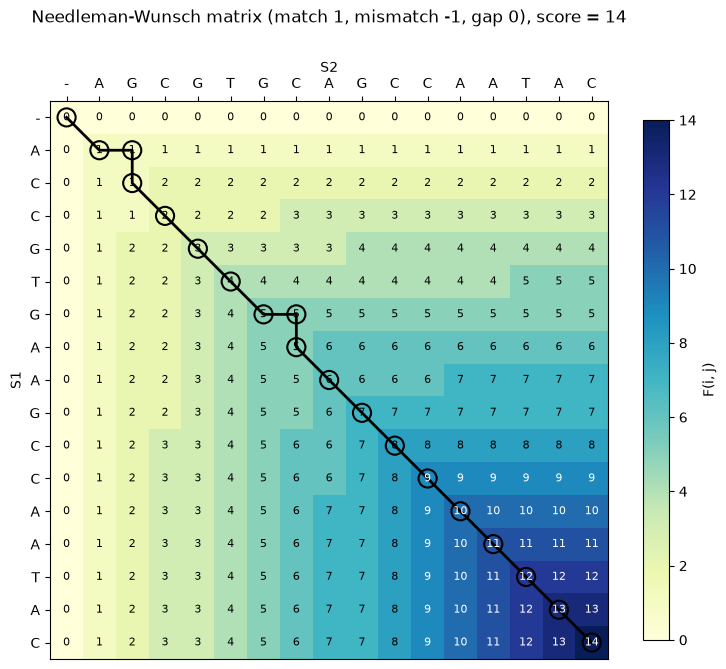

In [18]:
def plot_alignment_matrix(al, ax):
    F, s1, s2 = al["F"], al["s1"], al["s2"]
    im = ax.imshow(F, cmap="YlGnBu")
    for i in range(F.shape[0]):
        for j in range(F.shape[1]):
            ax.text(j, i, F[i, j], ha="center", va="center", fontsize=8,
                    color="white" if F[i, j] > F.max() * 0.6 else "black")
    py, px = zip(*al["path"])
    ax.plot(px, py, color="black", lw=2)
    ax.scatter(px, py, s=170, facecolors="none", edgecolors="black", lw=1.5)
    ax.set_xticks(range(F.shape[1]), ["-"] + list(s2))
    ax.set_yticks(range(F.shape[0]), ["-"] + list(s1))
    ax.xaxis.tick_top()
    ax.set_xlabel("S2")
    ax.xaxis.set_label_position("top")
    ax.set_ylabel("S1")
    match, mismatch, gap = al["params"]
    ax.set_title(f"Needleman-Wunsch matrix (match {match}, mismatch {mismatch}, gap {gap}), score = {al['score']}",
                 pad=28)
    return im


fig, ax = plt.subplots(figsize=(9, 9))
fig.colorbar(plot_alignment_matrix(al, ax), ax=ax, shrink=0.75, label="F(i, j)")
plt.show()

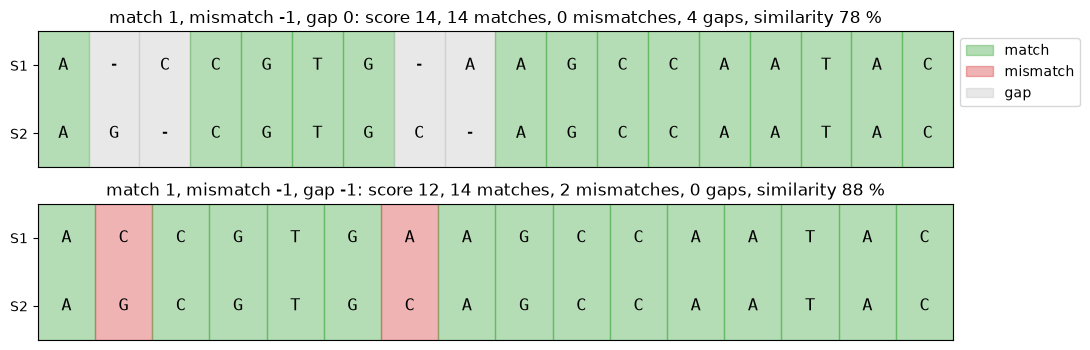


match = 1, mismatch = -1, gap = -1
S1  ACCGTGAAGCCAATAC
    |.||||.|||||||||
S2  AGCGTGCAGCCAATAC

score = 12, alignment length = 16, matches = 14, mismatches = 2, gaps = 0, similarity = 88 %


In [19]:
def plot_alignment_strip(al, ax, title):
    colors = {"match": "tab:green", "mismatch": "tab:red", "gap": "0.75"}
    for k, (a, b) in enumerate(zip(al["a1"], al["a2"])):
        kind = "gap" if "-" in (a, b) else ("match" if a == b else "mismatch")
        ax.add_patch(plt.Rectangle((k, 0), 1, 2, color=colors[kind], alpha=0.35))
        ax.text(k + 0.5, 1.5, a, ha="center", va="center", family="monospace", fontsize=12)
        ax.text(k + 0.5, 0.5, b, ha="center", va="center", family="monospace", fontsize=12)
    ax.set_xlim(0, len(al["a1"]))
    ax.set_ylim(0, 2)
    ax.set_yticks([0.5, 1.5], ["S2", "S1"])
    ax.set_xticks([])
    ax.set_title(title)
    for kind, c in colors.items():
        ax.add_patch(plt.Rectangle((0, 0), 0, 0, color=c, alpha=0.35, label=kind))


al_gap = global_alignment(S1, S2, match=1, mismatch=-1, gap=-1)
fig, axes = plt.subplots(2, 1, figsize=(11, 3.6))
for ax, a in zip(axes, [al, al_gap]):
    st = alignment_stats(a)
    plot_alignment_strip(a, ax, "match {}, mismatch {}, gap {}".format(*a["params"]) +
                         f": score {a['score']}, {st['matches']} matches, {st['mismatches']} mismatches, "
                         f"{st['gaps']} gaps, similarity {st['similarity']:.0f} %")
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

print()
show_alignment(al_gap)

#### Result

$S_1$ and $S_2$ have the same length (16 bases) and differ in only two positions: 2 (`C` / `G`) and 7 (`A` / `C`).

* With **match = 1, mismatch = -1, gap = 0** a gap costs nothing, while a mismatch costs 1. So the algorithm replaces
  each of the two mismatches with a pair of gaps (`C-` / `-G` and `-A` / `C-`). The result is **14 matches and 4 gaps
  in 18 columns, score = 14**, and all the bases that can be matched are matched.
* With **gap = -1** a pair of gaps costs $-2$, more than one mismatch ($-1$). The best alignment is then the one
  without gaps: the two sequences one under the other, **14 matches and 2 mismatches, score = 12, similarity 88 %**.

Both are correct global alignments: they cover both sequences from the first base to the last. The choice of the gap
penalty decides whether a substitution is described as a mismatch or as an insertion plus a deletion. For two
sequences of the same length that differ only by point substitutions, a negative gap penalty ($G = -1$) gives the
biologically more natural alignment.

The app works for any pair of sequences and any scores. For example, `show_alignment(global_alignment("GATTACA",
"GCATGCT", 1, -1, -1))` aligns two sequences of different lengths.

In [20]:
show_alignment(global_alignment("GATTACA", "GCATGCT", match=1, mismatch=-1, gap=-1))

match = 1, mismatch = -1, gap = -1
S1  G-ATTACA
    | | |.|.
S2  GCA-TGCT

score = 0, alignment length = 8, matches = 4, mismatches = 2, gaps = 2, similarity = 50 %
